# 2026 台北市長選舉：可重算證據與得票情境模型

**資料截止：2026-10-09｜投票日：2026-11-28**

本 notebook 包含 6 份民調、2022 / 2024 選舉、2025 五選區罷免與 2026 年施政評價。輸出是**當前民調平滑值、既有選票結構及條件得票率**；不將此視為個別候選人的勝選機率，也不將歷史選票直接當成 2026 年選票。

## TL;DR
- 民調採訪日期、題目及抽樣方式不相同；同機構 TVBS 從 5 月到 10 月的兩人支持度差距由 28 點變成 8 點。
- 2022 市長、2024 總統與 2025 五區罷免，分母及投票決策不同，保留為結構性診斷。
- 調整未表態者分配與投票參與係數，可立即重算**條件得票率**（不是實際選舉預測）。

## 1｜方法與假設

1. **原始民調**：保留每份調查的百分比、樣本、日期、問法；只對 `蔣/(蔣+沈)` 計算「兩位已表態者占比」，以免把未表態定義混入。
2. **描述性平滑**：依時間半衰期 28 天設定權重 `2 ** (-距今幾天/28)`；可改為 14/60 天做敏感度。這是**使用者可修改的描述性假設**，非訓練過的選舉預測器。
3. **條件得票情境**：固定已表態數字，將未表態比例按參數分流，並對兩邊已表態支持採相對投票參與係數。信民六人調查保留其他候選人；原本不投票/廢票的受訪比例自有效票分母排除。TVBS 不含其他候選人問法，不能用它推算完整六人選舉。
4. **非民調項目**：2022 / 2024 開票、2025 罷免、2022 議員席次與 2026 施政滿意度以不同指標呈現。沒有獨立驗證的選票轉換率，不編造加權加分。

### 2｜嵌入資料與來源

In [1]:
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
AS_OF=pd.Timestamp('2026-10-09')
POLLS = [{'end_date': '2026-05-05', 'field_period': '2026-05-04 ~ 05-05', 'pollster': '新台灣國策智庫／趨勢', 'chiang_pct': 52.9, 'shen_pct': 29.7, 'undecided_pct': 17.4, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': None, 'mode': '待核實', 'question_type': '兩位主要參選人', 'source_level': '媒體轉述發布', 'source': 'https://news.tvbs.com.tw/politics/3197625'}, {'end_date': '2026-05-26', 'field_period': '2026-05-21 ~ 05-26', 'pollster': 'TVBS', 'chiang_pct': 58.0, 'shen_pct': 30.0, 'undecided_pct': 13.0, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 901, 'mode': '市話 CATI', 'question_type': '兩位主要參選人，有投票意願者', 'source_level': '發布機構新聞', 'source': 'https://news.tvbs.com.tw/politics/3214867'}, {'end_date': '2026-06-22', 'field_period': '2026-06-21 ~ 06-22', 'pollster': '震傳媒／山水', 'chiang_pct': 55.2, 'shen_pct': 27.5, 'undecided_pct': None, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1074, 'mode': '市話 CATI', 'question_type': '兩位主要參選人', 'source_level': '發布機構新聞', 'source': 'https://www.zmedia.com.tw/Document/PoolDetail/42781'}, {'end_date': '2026-08-07', 'field_period': '2026-08-05 ~ 08-07', 'pollster': 'TPOC', 'chiang_pct': 48.4, 'shen_pct': 33.0, 'undecided_pct': 18.7, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1099, 'mode': '市話訪問（媒體報導）', 'question_type': '兩位主要參選人；其餘為無法選出任一候選人', 'source_level': '媒體轉述發布', 'source': 'https://news.tvbs.com.tw/politics/4007563'}, {'end_date': '2026-09-18', 'field_period': '2026-09-16 ~ 09-18', 'pollster': '信民／畢肯', 'chiang_pct': 41.7, 'shen_pct': 40.5, 'undecided_pct': 10.6, 'minor_pct': 2.1, 'no_vote_pct': 5.2, 'sample_n': 1076, 'mode': '市話752＋手機324 CATI', 'question_type': '六位登記參選者、含不投票／廢票', 'source_level': '調查方法與題目公開', 'source': 'https://news.tvbs.com.tw/politics/4025675'}, {'end_date': '2026-10-07', 'field_period': '2026-10-03, 10-05 ~ 10-07', 'pollster': 'TVBS', 'chiang_pct': 49.0, 'shen_pct': 41.0, 'undecided_pct': 11.0, 'minor_pct': None, 'no_vote_pct': None, 'sample_n': 1120, 'mode': '市話 CATI', 'question_type': '兩位主要參選人，有投票意願者', 'source_level': '發布機構新聞', 'source': 'https://news.tvbs.com.tw/politics/4033527'}]
CONTEXT = [{'year': 2022, 'type': '市長選舉', 'metric': '蔣萬安得票', 'value': 575590, 'unit': '票', 'basis': '台北市', 'use': '歷史背景，不當成2026票數', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '陳時中得票', 'value': 434558, 'unit': '票', 'basis': '台北市', 'use': '歷史背景，不當成2026票數', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '黃珊珊得票', 'value': 342141, 'unit': '票', 'basis': '台北市', 'use': '不同於2026自述投黃者', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2022, 'type': '市長選舉', 'metric': '有效票', 'value': 1360951, 'unit': '票', 'basis': '台北市', 'use': '票數正規化', 'source': 'https://election.ltn.com.tw/2022/realtime'}, {'year': 2022, 'type': '市長選舉', 'metric': '投票率', 'value': 67.7, 'unit': '%', 'basis': '台北市', 'use': '歷史參考', 'source': 'https://www.cna.com.tw/news/aipl/202211260299.aspx'}, {'year': 2024, 'type': '總統選舉', 'metric': '侯友宜得票', 'value': 587258, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '賴清德得票', 'value': 587899, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '柯文哲得票', 'value': 366854, 'unit': '票', 'basis': '台北市', 'use': '不同選舉，不直接轉成市長票', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2024, 'type': '總統選舉', 'metric': '投票率', 'value': 74.28, 'unit': '%', 'basis': '台北市', 'use': '歷史參考', 'source': 'https://govtw.org/election/2024-P'}, {'year': 2022, 'type': '議員選舉', 'metric': '國民黨席次', 'value': 30, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '民進黨席次', 'value': 21, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '民眾黨席次', 'value': 4, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2022, 'type': '議員選舉', 'metric': '其他席次', 'value': 6, 'unit': '席', 'basis': '台北市61席', 'use': '議會代表性，不能換算成市長票', 'source': 'https://www.cna.com.tw/news/aipl/202211260304.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '同意罷免合計', 'value': 330340, 'unit': '票', 'basis': '五選區，非全市', 'use': '只作動員背景，不轉換支持票', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '不同意罷免合計', 'value': 428596, 'unit': '票', 'basis': '五選區，非全市', 'use': '只作動員背景，不轉換支持票', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2025, 'type': '五席立委罷免', 'metric': '投票率', 'value': 59.03, 'unit': '%', 'basis': '五選區合計', 'use': '不能解讀成全市投票率', 'source': 'https://www.cna.com.tw/news/aipl/202507260215.aspx'}, {'year': 2026, 'type': '施政評價', 'metric': '10月現任市長滿意', 'value': 52.0, 'unit': '%', 'basis': 'TVBS 10月調查', 'use': '獨立測量指標，未建立選票轉換率', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '施政評價', 'metric': '10月現任市長不滿意', 'value': 35.0, 'unit': '%', 'basis': 'TVBS 10月調查', 'use': '獨立測量指標，未建立選票轉換率', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '歷史選票自述交叉表', 'metric': '10月自述2022投黃珊珊者轉支持沈', 'value': 53.0, 'unit': '%', 'basis': 'TVBS 10月，2022自述投黃者', 'use': '不可直接乘2022全部實際黃珊珊票', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '歷史選票自述交叉表', 'metric': '10月自述2022投黃珊珊者轉支持蔣', 'value': 39.0, 'unit': '%', 'basis': 'TVBS 10月，2022自述投黃者', 'use': '不可直接乘2022全部實際黃珊珊票', 'source': 'https://news.tvbs.com.tw/politics/4033530'}, {'year': 2026, 'type': '問卷投票意願', 'metric': '10月表示會投票', 'value': 92.0, 'unit': '%', 'basis': 'TVBS 10月，表示一定或可能投票', 'use': '自述意願非實際投票率', 'source': 'https://news.tvbs.com.tw/politics/4033527'}, {'year': 2026, 'type': '機構推估', 'metric': 'TVBS 預估投票率', 'value': 71.0, 'unit': '%', 'basis': 'TVBS推估，不是觀測結果', 'use': '僅作情境參數候選', 'source': 'https://news.tvbs.com.tw/politics/4033527'}]
RECALL = [{'district': '王鴻薇（第三選區）', 'yes': 76463, 'no': 86311}, {'district': '李彥秀（第四選區）', 'yes': 78560, 'no': 105169}, {'district': '羅智強（第六選區）', 'yes': 56726, 'no': 74808}, {'district': '徐巧芯（第七選區）', 'yes': 62633, 'no': 75401}, {'district': '賴士葆（第八選區）', 'yes': 55958, 'no': 86907}]
polls=pd.DataFrame(POLLS)
context=pd.DataFrame(CONTEXT)
recall=pd.DataFrame(RECALL)
polls['end_date']=pd.to_datetime(polls['end_date'])
polls['pair_chiang_share_pct']=100*polls['chiang_pct']/(polls['chiang_pct']+polls['shen_pct'])
display(polls[['end_date','pollster','chiang_pct','shen_pct','undecided_pct','minor_pct','no_vote_pct','sample_n','mode','question_type','source']])

,end_date,pollster,chiang_pct,shen_pct,undecided_pct,minor_pct,no_vote_pct,sample_n,mode,question_type,source
0,2026-05-05,新台灣國策智庫／趨勢,52.9,29.7,17.4,NaN,NaN,NaN,待核實,兩位主要參選人,https://news.tvbs.com.tw/politics/3197625
1,2026-05-26,TVBS,58.0,30.0,13.0,NaN,NaN,901.0,市話 CATI,兩位主要參選人，有投票意願者,https://news.tvbs.com.tw/politics/3214867
2,2026-06-22,震傳媒／山水,55.2,27.5,NaN,NaN,NaN,1074.0,市話 CATI,兩位主要參選人,https://www.zmedia.com.tw/Document/PoolDetail/...
3,2026-08-07,TPOC,48.4,33.0,18.7,NaN,NaN,1099.0,市話訪問（媒體報導）,兩位主要參選人；其餘為無法選出任一候選人,https://news.tvbs.com.tw/politics/4007563
4,2026-09-18,信民／畢肯,41.7,40.5,10.6,2.1,5.2,1076.0,市話752＋手機324 CATI,六位登記參選者、含不投票／廢票,https://news.tvbs.com.tw/politics/4025675
5,2026-10-07,TVBS,49.0,41.0,11.0,NaN,NaN,1120.0,市話 CATI,兩位主要參選人，有投票意願者,https://news.tvbs.com.tw/politics/4033527


### 3｜資料一致性

In [2]:
assert len(polls)==6
assert len(context)>=20
assert int(recall['yes'].sum())==330340
assert int(recall['no'].sum())==428596
assert sum([30,21,4,6])==61
assert sum([587899,587258,366854])==1542011
assert all((polls['chiang_pct']>0)&(polls['shen_pct']>0))
# 不以100%作硬限制：報導先四捨五入，TVBS 10月49+41+11=101。
for _,row in polls.iterrows():
    parts=[row[k] for k in ['chiang_pct','shen_pct','undecided_pct','minor_pct','no_vote_pct'] if pd.notna(row[k])]
    if row['pollster']!='震傳媒／山水':
        assert abs(sum(parts)-100)<=1.1, (row['pollster'],sum(parts))
print('PASS: 六份民調；歷史票數與席次；2025罷免合計；容許公佈百分比的四捨五入。')

PASS: 六份民調；歷史票數與席次；2025罷免合計；容許公佈百分比的四捨五入。


## 4｜民調時序：不同調查機構及問法不可直接視為同一追蹤樣本

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26032 (\N{CJK UNIFIED IDEOGRAPH-65B0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 21488 (\N{CJK UNIFIED IDEOGRAPH-53F0}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 28771 (\N{CJK UNIFIED IDEOGRAPH-7063}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 22283 (\N{CJK UNIFIED IDEOGRAPH-570B}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 31574 (\N{CJK UNIFIED IDEOGRAPH-7B56}) missing from font(s) DejaVu Sans.
  fig.c

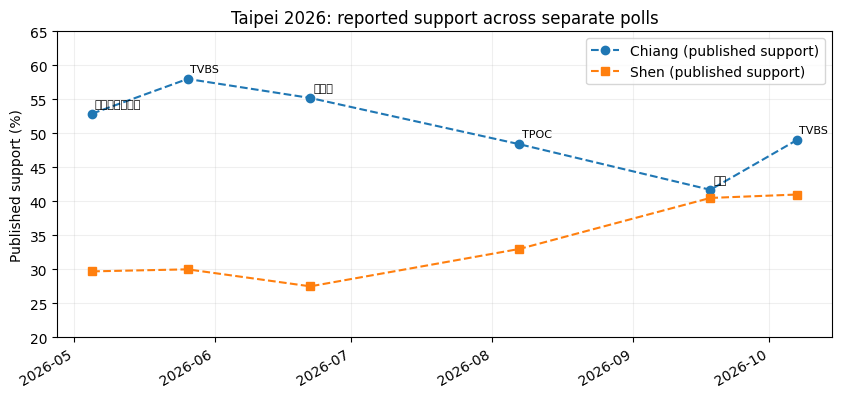

In [3]:
fig,ax=plt.subplots(figsize=(10,4.5))
polls_sorted=polls.sort_values('end_date')
ax.plot(polls_sorted['end_date'],polls_sorted['chiang_pct'],marker='o',linestyle='--',label='Chiang (published support)')
ax.plot(polls_sorted['end_date'],polls_sorted['shen_pct'],marker='s',linestyle='--',label='Shen (published support)')
for _,r in polls_sorted.iterrows():
    ax.annotate(r['pollster'].split('／')[0],(r['end_date'],r['chiang_pct']),xytext=(2,5),textcoords='offset points',fontsize=8)
ax.set(ylabel='Published support (%)',title='Taipei 2026: reported support across separate polls',ylim=(20,65))
ax.grid(alpha=.2);ax.legend();fig.autofmt_xdate();plt.show()

## 5｜現時民調的描述性平滑（不是投票日預測）

In [4]:
def smoothed_pair_share(half_life_days=28, earliest='2026-08-01'):
    x=polls[polls['end_date']>=pd.Timestamp(earliest)].copy()
    x['days_old']=(AS_OF-x['end_date']).dt.days
    x['time_weight']=2**(-x['days_old']/half_life_days)
    value=np.average(x['pair_chiang_share_pct'],weights=x['time_weight'])
    return value,x
rows=[]
for half_life in [14,28,60]:
    s,d=smoothed_pair_share(half_life)
    rows.append({'half_life_days':half_life,'conditional_share_chiang_pct':round(s,2),'conditional_share_shen_pct':round(100-s,2),'poll_count':len(d)})
smooth_table=pd.DataFrame(rows)
display(smooth_table)
print('半衰期=28日之各調查權重（只看8月以後）：')
_,w=smoothed_pair_share(28)
display(w[['pollster','end_date','pair_chiang_share_pct','days_old','time_weight']])

,half_life_days,conditional_share_chiang_pct,conditional_share_shen_pct,poll_count
0,14,53.61,46.39,3
1,28,53.79,46.21,3
2,60,54.23,45.77,3


半衰期=28日之各調查權重（只看8月以後）：


,pollster,end_date,pair_chiang_share_pct,days_old,time_weight
3,TPOC,2026-08-07,59.459459,63,0.210224
4,信民／畢肯,2026-09-18,50.729927,21,0.594604
5,TVBS,2026-10-07,54.444444,2,0.951695


## 6｜條件得票率情境：未表態者與相對投票參與

In [5]:
def conditional_vote_share(pollster, undecided_to_shen=.5, chiang_turnout=1.0, shen_turnout=1.0):
    row=polls[polls['pollster']==pollster].sort_values('end_date').iloc[-1]
    if pd.isna(row['undecided_pct']):
        raise ValueError('缺少獨立未表態比例，不得自行填補')
    c=row['chiang_pct']+(1-undecided_to_shen)*row['undecided_pct']
    s=row['shen_pct']+undecided_to_shen*row['undecided_pct']
    other=0 if pd.isna(row['minor_pct']) else row['minor_pct']
    c*=chiang_turnout;s*=shen_turnout
    den=c+s+other
    return {'chiang_pct':100*c/den,'shen_pct':100*s/den,'other_pct':100*other/den}
scenario_table=[]
for agency in ['信民／畢肯','TVBS']:
    for allocation in [.25,.50,.75]:
        result=conditional_vote_share(agency,allocation)
        scenario_table.append({'basis':agency,'undecided_to_shen_pct':100*allocation,**{k:round(v,2) for k,v in result.items()}})
display(pd.DataFrame(scenario_table))

,basis,undecided_to_shen_pct,chiang_pct,shen_pct,other_pct
0,信民／畢肯,25.0,52.32,45.47,2.21
1,信民／畢肯,50.0,49.53,48.26,2.21
2,信民／畢肯,75.0,46.73,51.05,2.21
3,TVBS,25.0,56.68,43.32,0.00
4,TVBS,50.0,53.96,46.04,0.00
5,TVBS,75.0,51.24,48.76,0.00


### 7｜情境敏感度曲線：固定民調，只改假設

/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 20449 (\N{CJK UNIFIED IDEOGRAPH-4FE1}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 27665 (\N{CJK UNIFIED IDEOGRAPH-6C11}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 65295 (\N{FULLWIDTH SOLIDUS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 30050 (\N{CJK UNIFIED IDEOGRAPH-7562}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/pyvenv/lib/python3.13/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 32943 (\N{CJK UNIFIED IDEOGRAPH-80AF}) missing from font(s) DejaVu Sans.
  fig.canvas.pri

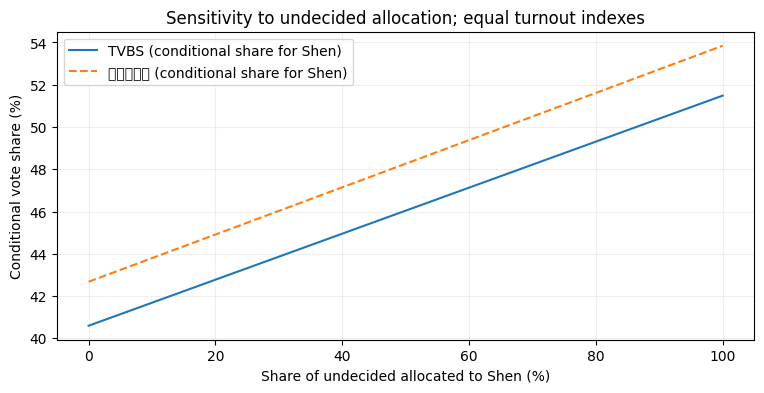

In [6]:
fig,ax=plt.subplots(figsize=(9,4))
alloc=np.linspace(0,1,101)
for agency,style in [('TVBS','-'),('信民／畢肯','--')]:
    shares=[conditional_vote_share(agency,a)['shen_pct'] for a in alloc]
    ax.plot(alloc*100,shares,linestyle=style,label=f'{agency} (conditional share for Shen)')
ax.set(xlabel='Share of undecided allocated to Shen (%)',ylabel='Conditional vote share (%)',title='Sensitivity to undecided allocation; equal turnout indexes')
ax.grid(alpha=.2);ax.legend();plt.show()

### 8｜投票參與敏感度：只是一個反事實參數

In [7]:
turnout_cases=[]
for rel in [.9,1.0,1.1]:
    vals=conditional_vote_share('信民／畢肯',.5,chiang_turnout=rel,shen_turnout=1.0)
    turnout_cases.append({'chiang_relative_turnout':rel,'shen_relative_turnout':1.0,**{k:round(v,2) for k,v in vals.items()}})
display(pd.DataFrame(turnout_cases))

,chiang_relative_turnout,shen_relative_turnout,chiang_pct,shen_pct,other_pct
0,0.9,1.0,46.90,50.78,2.33
1,1.0,1.0,49.53,48.26,2.21
2,1.1,1.0,51.91,45.98,2.11


## 9｜非民調資料：結構指標，不能合併成票數

In [8]:
display(context[['year','type','metric','value','unit','basis','use']])

,year,type,metric,value,unit,basis,use
0,2022,市長選舉,蔣萬安得票,575590.00,票,台北市,歷史背景，不當成2026票數
1,2022,市長選舉,陳時中得票,434558.00,票,台北市,歷史背景，不當成2026票數
2,2022,市長選舉,黃珊珊得票,342141.00,票,台北市,不同於2026自述投黃者
3,2022,市長選舉,有效票,1360951.00,票,台北市,票數正規化
4,2022,市長選舉,投票率,67.70,%,台北市,歷史參考
5,2024,總統選舉,侯友宜得票,587258.00,票,台北市,不同選舉，不直接轉成市長票
6,2024,總統選舉,賴清德得票,587899.00,票,台北市,不同選舉，不直接轉成市長票
7,2024,總統選舉,柯文哲得票,366854.00,票,台北市,不同選舉，不直接轉成市長票
8,2024,總統選舉,投票率,74.28,%,台北市,歷史參考
9,2022,議員選舉,國民黨席次,30.00,席,台北市61席,議會代表性，不能換算成市長票


### 10｜2025 年五選區罷免：不同於市長選舉

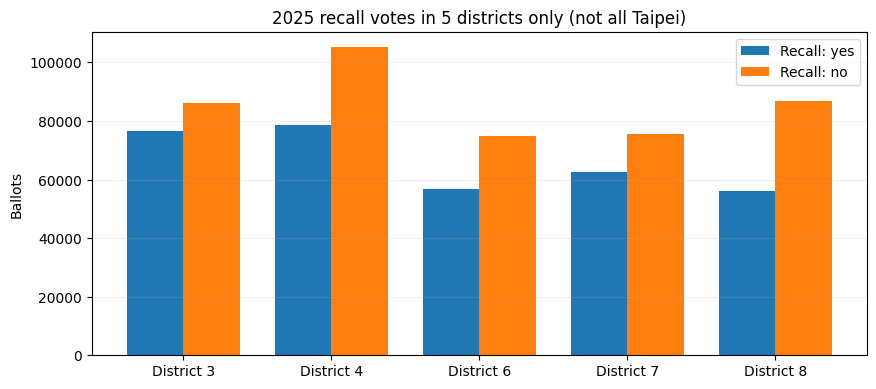

總同意: 330340 總不同意: 428596


In [9]:
fig,ax=plt.subplots(figsize=(10,4.2))
x=np.arange(len(recall));width=.38
ax.bar(x-width/2,recall['yes'],width,label='Recall: yes')
ax.bar(x+width/2,recall['no'],width,label='Recall: no')
ax.set_xticks(x,[f'District {k}' for k in [3,4,6,7,8]])
ax.set(title='2025 recall votes in 5 districts only (not all Taipei)',ylabel='Ballots');ax.grid(axis='y',alpha=.2);ax.legend();plt.show()
print('總同意:',recall['yes'].sum(),'總不同意:',recall['no'].sum())

## 11｜結論與再現

這份模型已將核對過的**現有數字實際填入**，並可更動未表態者流向、各方相對投票參與、以及民調時間半衰期。圖表顯示的是民調觀察與條件計算，**不是對 2026/11/28 選舉結果的預測**。

要把它升級成統計校準過的選舉預測器，至少需要多屆同時間點、同問法民調與實際開票結果配對，估計機構效應、全局系統性誤差、未表態者變化及 turnout model。目前非民調變數缺少合理的票數轉換係數，因此不會擅自加總成統一分數。

資料來源可由上方 `polls['source']`、`context['source']` 欄逐一點開，更新數字後重新執行全部儲存格。